# Отчет по домашнему заданию
## Вариант 19

**Выполнил:** Сорокин Никита
**Группа:** ИУ5-35Б  

---

### Результаты генерации условий для варианта 19
Формула инициализации случайных чисел: `seed(Variant + 1113332224456)` для `Variant = 19`:
* **Структура данных:** Массив
* **Метод выделения памяти:** Анонимное отображение (`mmap`)
* **Список функций (действий):**
  1. `Создание массива заданного размера`
  2. `Заполнение случайными числами`
  3. `Получение списка нечетных чисел`
  4. `Подсчет количества простых чисел`
  5. `Реверсирование элементов массива`

### 1. Заголовочный файл C (`array.h`)

In [ ]:
%%writefile array.h
#ifndef ARRAY_H
#define ARRAY_H

#include <stddef.h>

#ifdef __cplusplus
extern "C" {
#endif

// Создание массива заданного размера через анонимное отображение (mmap)
int* create_array(size_t size);

// Освобождение памяти массива (munmap)
void free_array(int* ptr, size_t size);

// Заполнение массива случайными числами в диапазоне [min_val, max_val]
void fill_random(int* ptr, size_t size, int min_val, int max_val);

// Получение списка нечетных чисел
size_t get_odd_numbers(const int* src, size_t src_size, int* dst);

// Подсчет количества простых чисел в массиве
size_t count_primes(const int* ptr, size_t size);

// Реверсирование элементов массива на месте
void reverse_array(int* ptr, size_t size);

#ifdef __cplusplus
}
#endif

#endif // ARRAY_H


### 2. Реализация функций на FASM (`array.asm`)

In [ ]:
%%writefile array.asm
; array.asm - Реализация функций работы с массивом на FASM (x86_64 Linux)
format ELF64

section '.text' executable

public create_array
public free_array
public fill_random
public get_odd_numbers
public count_primes
public reverse_array

; Номера системных вызовов Linux x86_64
SYS_MMAP      equ 9
SYS_MUNMAP    equ 11
SYS_GETRANDOM equ 318

; Флаги mmap
PROT_READ     equ 1
PROT_WRITE    equ 2
MAP_PRIVATE   equ 0x02
MAP_ANONYMOUS equ 0x20

; -------------------------------------------------------------
; int* create_array(size_t size)
; rdi = size (в элементах int)
; -------------------------------------------------------------
create_array:
    push rbp
    mov rbp, rsp

    shl rdi, 2               ; size * sizeof(int)
    jz .err                  ; если size == 0, возврат NULL

    mov rsi, rdi             ; length
    xor rdi, rdi             ; addr = NULL
    mov rdx, PROT_READ or PROT_WRITE
    mov r10, MAP_PRIVATE or MAP_ANONYMOUS
    mov r8, -1               ; fd = -1
    xor r9, r9               ; offset = 0
    mov rax, SYS_MMAP
    syscall

    cmp rax, -4095
    jae .err
    leave
    ret
.err:
    xor rax, rax
    leave
    ret

; -------------------------------------------------------------
; void free_array(int* ptr, size_t size)
; rdi = ptr, rsi = size
; -------------------------------------------------------------
free_array:
    push rbp
    mov rbp, rsp

    test rdi, rdi
    jz .done
    test rsi, rsi
    jz .done

    shl rsi, 2               ; length = size * 4
    mov rax, SYS_MUNMAP
    syscall

.done:
    leave
    ret

; -------------------------------------------------------------
; void fill_random(int* ptr, size_t size, int min_val, int max_val)
; rdi = ptr, rsi = size, edx = min_val, ecx = max_val
; -------------------------------------------------------------
fill_random:
    push rbp
    mov rbp, rsp
    push r12
    push r13
    push r14
    push r15
    push rbx

    test rdi, rdi
    jz .fill_done
    test rsi, rsi
    jz .fill_done

    mov r12, rdi             ; ptr
    mov r13, rsi             ; size
    mov r14d, edx            ; min_val
    mov r15d, ecx            ; max_val
    sub r15d, r14d           ; range = max - min + 1
    inc r15d
    cmp r15d, 0
    jle .fill_done

    xor rbx, rbx             ; i = 0
.loop_fill:
    cmp rbx, r13
    jge .fill_done

    sub rsp, 16
    mov rdi, rsp
    mov rsi, 4
    xor rdx, rdx
    mov rax, SYS_GETRANDOM
    syscall
    mov eax, dword [rsp]
    add rsp, 16

    ; eax = abs(eax)
    mov edx, eax
    sar edx, 31
    xor eax, edx
    sub eax, edx

    xor rdx, rdx
    div r15d                 ; edx = eax % range
    add edx, r14d            ; val = min_val + edx

    mov dword [r12 + rbx*4], edx
    inc rbx
    jmp .loop_fill

.fill_done:
    pop rbx
    pop r15
    pop r14
    pop r13
    pop r12
    leave
    ret

; -------------------------------------------------------------
; size_t get_odd_numbers(const int* src, size_t src_size, int* dst)
; rdi = src, rsi = src_size, rdx = dst
; -------------------------------------------------------------
get_odd_numbers:
    push rbp
    mov rbp, rsp

    xor rax, rax             ; count = 0
    test rdi, rdi
    jz .odd_done
    test rdx, rdx
    jz .odd_done
    test rsi, rsi
    jz .odd_done

    xor rcx, rcx             ; i = 0
.loop_odd:
    cmp rcx, rsi
    jge .odd_done

    mov r8d, dword [rdi + rcx*4]
    test r8d, 1
    jz .skip_odd

    mov dword [rdx + rax*4], r8d
    inc rax

.skip_odd:
    inc rcx
    jmp .loop_odd

.odd_done:
    leave
    ret

; -------------------------------------------------------------
; size_t count_primes(const int* ptr, size_t size)
; rdi = ptr, rsi = size
; -------------------------------------------------------------
count_primes:
    push rbp
    mov rbp, rsp
    push rbx
    push r12

    xor rbx, rbx             ; total prime count = 0
    test rdi, rdi
    jz .prime_done
    test rsi, rsi
    jz .prime_done

    xor r12, r12             ; i = 0
.loop_prime:
    cmp r12, rsi
    jge .prime_done

    mov edx, dword [rdi + r12*4]
    cmp edx, 2
    jl .next_elem

    mov ecx, 2
.check_div:
    mov eax, ecx
    imul eax, ecx
    cmp eax, edx
    jg .is_prime_val

    mov eax, edx
    push rdx
    xor rdx, rdx
    div ecx
    pop r8
    test rdx, rdx
    jz .next_elem

    inc ecx
    jmp .check_div

.is_prime_val:
    inc rbx

.next_elem:
    inc r12
    jmp .loop_prime

.prime_done:
    mov rax, rbx
    pop r12
    pop rbx
    leave
    ret

; -------------------------------------------------------------
; void reverse_array(int* ptr, size_t size)
; rdi = ptr, rsi = size
; -------------------------------------------------------------
reverse_array:
    push rbp
    mov rbp, rsp

    test rdi, rdi
    jz .rev_done
    cmp rsi, 1
    jle .rev_done

    xor rax, rax             ; left = 0
    mov r8, rsi
    dec r8                   ; right = size - 1

.loop_rev:
    cmp rax, r8
    jge .rev_done

    mov ecx, dword [rdi + rax*4]
    mov edx, dword [rdi + r8*4]

    mov dword [rdi + rax*4], edx
    mov dword [rdi + r8*4], ecx

    inc rax
    dec r8
    jmp .loop_rev

.rev_done:
    leave
    ret


### 3. Демонстрационная программа на C (`main.c`)

In [ ]:
%%writefile main.c
#include <stdio.h>
#include <stdlib.h>
#include "array.h"

void print_array(const char* label, const int* arr, size_t size) {
    printf("%s [размер %zu]: ", label, size);
    for (size_t i = 0; i < size; ++i) {
        printf("%d ", arr[i]);
    }
    printf("\n");
}

int main() {
    size_t n = 12;
    printf("=== Демонстрация работы с массивом в анонимной памяти (FASM + C) ===\n\n");

    // 1. Создание массива заданного размера через mmap
    int* arr = create_array(n);
    if (!arr) {
        fprintf(stderr, "Ошибка: не удалось выделить память через mmap!\n");
        return 1;
    }
    printf("1. Массив успешно создан в анонимном отображении (mmap) по адресу: %p\n", (void*)arr);

    // 2. Заполнение случайными числами
    fill_random(arr, n, 1, 50);
    print_array("2. Исходный массив (заполнен случайными числами [1..50])", arr, n);

    // 3. Подсчет количества простых чисел
    size_t primes_count = count_primes(arr, n);
    printf("3. Количество простых чисел в массиве: %zu\n", primes_count);

    // 4. Получение списка нечетных чисел
    int* odd_arr = create_array(n);
    if (odd_arr) {
        size_t odd_count = get_odd_numbers(arr, n, odd_arr);
        print_array("4. Список нечетных чисел", odd_arr, odd_count);
        free_array(odd_arr, n);
    }

    // 5. Реверсирование элементов массива
    reverse_array(arr, n);
    print_array("5. Массив после реверсирования", arr, n);

    // Освобождение памяти
    free_array(arr, n);
    printf("\nПамять успешно освобождена через munmap.\n");

    return 0;
}


### 4. Makefile

In [ ]:
%%writefile Makefile
CC = gcc
ASM = fasm
CFLAGS = -Wall -Wextra -O2

TARGET = main_prog
OBJS = main.o array.o

all: $(TARGET)

$(TARGET): $(OBJS)
	$(CC) $(CFLAGS) -o $(TARGET) $(OBJS)

main.o: main.c array.h
	$(CC) $(CFLAGS) -c main.c -o main.o

array.o: array.asm
	$(ASM) array.asm array.o

clean:
	rm -f $(OBJS) $(TARGET)

run: all
	./$(TARGET)

.PHONY: all clean run


### 5. Инструкция по компиляции и запуску

In [ ]:
!make run

## Результаты

![Снимок экрана 2026-11-03 141037.png](<attachment:Снимок экрана 2026-11-03 141037.png>)
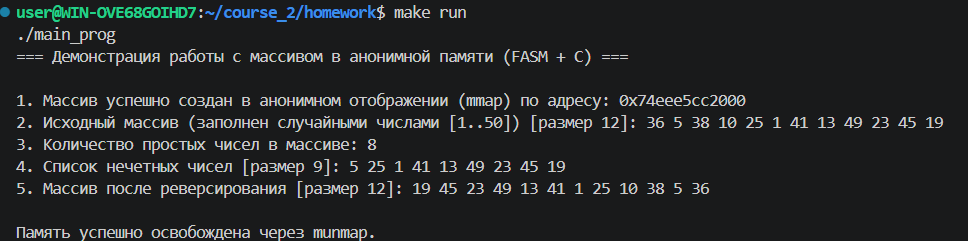